In [3]:
!pip install pandas numpy scikit-learn xgboost matplotlib seaborn
!pip install xgboost lightgbm catboost


  Obtaining dependency information for xgboost from https://files.pythonhosted.org/packages/1f/3d/1661dd114a914a67e3f7ab66fa1382e7599c2a8c340f314ad30a3e2b4d08/xgboost-3.2.0-py3-none-win_amd64.whl.metadata
  Using cached xgboost-3.2.0-py3-none-win_amd64.whl.metadata (2.1 kB)
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB 1.4 MB/s eta 0:01:15
   ---------------------------------------- 0.1/101.7 MB 1.3 MB/s eta 0:01:18
   ---------------------------------------- 0.3/101.7 MB 2.0 MB/s eta 0:00:50
   ---------------------------------------- 0.5/101.7 MB 2.9 MB/s eta 0:00:36
   ---------------------------------------- 0.8/101.7 MB 3.4 MB/s eta 0:00:30
   ---------------------------------------- 1.1/101.7 MB 4.0 MB/s eta 0:00:26
   ---------------------------------------- 1.2/101.7 MB 4.2 MB/s eta 0:00:24
   ---------------------------------------- 1.2/101.7 MB 4.2 MB/s eta 0:00:24
   ---------------------------

ERROR: Could not install packages due to an OSError: [Errno 28] No space left on device



  Obtaining dependency information for xgboost from https://files.pythonhosted.org/packages/1f/3d/1661dd114a914a67e3f7ab66fa1382e7599c2a8c340f314ad30a3e2b4d08/xgboost-3.2.0-py3-none-win_amd64.whl.metadata
  Using cached xgboost-3.2.0-py3-none-win_amd64.whl.metadata (2.1 kB)
  Obtaining dependency information for lightgbm from https://files.pythonhosted.org/packages/d5/0b/c5c17d862b12ce292f24cd85d40f2f8f8981668fbdbd43fdc2625eccbc79/lightgbm-4.7.0-py3-none-win_amd64.whl.metadata
  Using cached lightgbm-4.7.0-py3-none-win_amd64.whl.metadata (18 kB)
  Obtaining dependency information for catboost from https://files.pythonhosted.org/packages/a9/af/36048fdd08eca7876716176c30acf0e7ff1dfb1f53d0b93a021537e26601/catboost-1.2.10-cp311-cp311-win_amd64.whl.metadata
  Using cached catboost-1.2.10-cp311-cp311-win_amd64.whl.metadata (1.5 kB)
  Obtaining dependency information for narwhals>=1.15 from https://files.pythonhosted.org/packages/7e/85/a5bfaebfd305ac18b57b0854d74e37e586809061a91fda62f0bd50c85

ERROR: Exception:
Traceback (most recent call last):
  File "C:\Users\tanve\anaconda3\Lib\site-packages\pip\_vendor\urllib3\response.py", line 438, in _error_catcher
    yield
  File "C:\Users\tanve\anaconda3\Lib\site-packages\pip\_vendor\urllib3\response.py", line 561, in read
    data = self._fp_read(amt) if not fp_closed else b""
           ^^^^^^^^^^^^^^^^^^
  File "C:\Users\tanve\anaconda3\Lib\site-packages\pip\_vendor\urllib3\response.py", line 527, in _fp_read
    return self._fp.read(amt) if amt is not None else self._fp.read()
           ^^^^^^^^^^^^^^^^^^
  File "C:\Users\tanve\anaconda3\Lib\site-packages\pip\_vendor\cachecontrol\filewrapper.py", line 94, in read
    self.__buf.write(data)
  File "C:\Users\tanve\anaconda3\Lib\tempfile.py", line 483, in func_wrapper
    return func(*args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^
OSError: [Errno 28] No space left on device

During handling of the above exception, another exception occurred:

Traceback (most recent call last):

In [1]:
import numpy as np 
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder


# xgboost 
from xgboost import XGBClassifier

# LightGBM
from lightgbm import LGBMClassifier

# CatBoost
from catboost import CatBoostClassifier

# Scikit-learn models
from sklearn.ensemble import (
    ExtraTreesClassifier,
    RandomForestClassifier
)
# Missing-value handling
from sklearn.impute import SimpleImputer

# Validation
from sklearn.model_selection import GroupShuffleSplit


# Import train-test split
from sklearn.model_selection import train_test_split

# Import evaluation metrics
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import f1_score


In [ ]:
#read csv file
train_data=pd.read_csv("train.csv")
test_data=pd.read_csv("test.csv")

C:\Users\HP\AppData\Local\Temp\ipykernel_17544\3241763137.py:2: DtypeWarning: Columns (0: Monthly_Balance) have mixed types. Specify dtype option on import or set low_memory=False.
  train_data=pd.read_csv("train.csv")


# analysis data

In [ ]:
train_data.head()



,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,0x1602,CUS_0xd40,January,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3,7,11.27,4.0,_,809.98,26.822620,22 Years and 1 Months,No,49.574949,80.41529543900253,High_spent_Small_value_payments,312.49408867943663,Good
1,0x1603,CUS_0xd40,February,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",-1,NaN,11.27,4.0,Good,809.98,31.944960,NaN,No,49.574949,118.28022162236736,Low_spent_Large_value_payments,284.62916249607184,Good
2,0x1604,CUS_0xd40,March,Aaron Maashoh,-500,821-00-0265,Scientist,19114.12,NaN,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3,7,_,4.0,Good,809.98,28.609352,22 Years and 3 Months,No,49.574949,81.699521264648,Low_spent_Medium_value_payments,331.2098628537912,Good
3,0x1605,CUS_0xd40,April,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",5,4,6.27,4.0,Good,809.98,31.377862,22 Years and 4 Months,No,49.574949,199.4580743910713,Low_spent_Small_value_payments,223.45130972736786,Good
4,0x1606,CUS_0xd40,May,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",6,NaN,11.27,4.0,Good,809.98,24.797347,22 Years and 5 Months,No,49.574949,41.420153086217326,High_spent_Medium_value_payments,341.48923103222177,Good


In [ ]:
test_data.head()

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance
0,0x160a,CUS_0xd40,September,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3,7,11.27,2022.0,Good,809.98,35.030402,22 Years and 9 Months,No,49.574949,236.64268203272135,Low_spent_Small_value_payments,186.26670208571772
1,0x160b,CUS_0xd40,October,Aaron Maashoh,24,821-00-0265,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3,9,13.27,4.0,Good,809.98,33.053114,22 Years and 10 Months,No,49.574949,21.465380264657146,High_spent_Medium_value_payments,361.44400385378196
2,0x160c,CUS_0xd40,November,Aaron Maashoh,24,821-00-0265,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",-1,4,12.27,4.0,Good,809.98,33.811894,NaN,No,49.574949,148.23393788500925,Low_spent_Medium_value_payments,264.67544623342997
3,0x160d,CUS_0xd40,December,Aaron Maashoh,24_,821-00-0265,Scientist,19114.12,NaN,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",4,5,11.27,4.0,Good,809.98,32.430559,23 Years and 0 Months,No,49.574949,39.08251089460281,High_spent_Medium_value_payments,343.82687322383634
4,0x1616,CUS_0x21b1,September,Rick Rothackerj,28,004-07-5839,_______,34847.84,3037.986667,2,4,6,1,Credit-Builder Loan,3,1,5.42,5.0,Good,605.03,25.926822,27 Years and 3 Months,No,18.816215,39.684018417945296,High_spent_Large_value_payments,485.2984336755923


In [ ]:
train_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 28 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   ID                        100000 non-null  str    
 1   Customer_ID               100000 non-null  str    
 2   Month                     100000 non-null  str    
 3   Name                      90015 non-null   str    
 4   Age                       100000 non-null  str    
 5   SSN                       100000 non-null  str    
 6   Occupation                100000 non-null  str    
 7   Annual_Income             100000 non-null  str    
 8   Monthly_Inhand_Salary     84998 non-null   float64
 9   Num_Bank_Accounts         100000 non-null  int64  
 10  Num_Credit_Card           100000 non-null  int64  
 11  Interest_Rate             100000 non-null  int64  
 12  Num_of_Loan               100000 non-null  str    
 13  Type_of_Loan              88592 non-null   str    
 14  

In [ ]:
test_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 27 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ID                        50000 non-null  str    
 1   Customer_ID               50000 non-null  str    
 2   Month                     50000 non-null  str    
 3   Name                      44985 non-null  str    
 4   Age                       50000 non-null  str    
 5   SSN                       50000 non-null  str    
 6   Occupation                50000 non-null  str    
 7   Annual_Income             50000 non-null  str    
 8   Monthly_Inhand_Salary     42502 non-null  float64
 9   Num_Bank_Accounts         50000 non-null  int64  
 10  Num_Credit_Card           50000 non-null  int64  
 11  Interest_Rate             50000 non-null  int64  
 12  Num_of_Loan               50000 non-null  str    
 13  Type_of_Loan              44296 non-null  str    
 14  Delay_from_due_da

In [ ]:
train_data.describe()

,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Delay_from_due_date,Num_Credit_Inquiries,Credit_Utilization_Ratio,Total_EMI_per_month
count,84998.000000,100000.000000,100000.00000,100000.000000,100000.000000,98035.000000,100000.000000,100000.000000
mean,4194.170850,17.091280,22.47443,72.466040,21.068780,27.754251,32.285173,1403.118217
std,3183.686167,117.404834,129.05741,466.422621,14.860104,193.177339,5.116875,8306.041270
min,303.645417,-1.000000,0.00000,1.000000,-5.000000,0.000000,20.000000,0.000000
25%,1625.568229,3.000000,4.00000,8.000000,10.000000,3.000000,28.052567,30.306660
50%,3093.745000,6.000000,5.00000,13.000000,18.000000,6.000000,32.305784,69.249473
75%,5957.448333,7.000000,7.00000,20.000000,28.000000,9.000000,36.496663,161.224249
max,15204.633333,1798.000000,1499.00000,5797.000000,67.000000,2597.000000,50.000000,82331.000000


In [ ]:
test_data.describe()

,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Delay_from_due_date,Num_Credit_Inquiries,Credit_Utilization_Ratio,Total_EMI_per_month
count,42502.000000,50000.000000,50000.000000,50000.000000,50000.000000,48965.000000,50000.000000,50000.000000
mean,4182.004291,16.838260,22.921480,68.772640,21.052640,30.080200,32.279581,1491.304305
std,3174.109304,116.396848,129.314804,451.602363,14.860397,196.984121,5.106238,8595.647887
min,303.645417,-1.000000,0.000000,1.000000,-5.000000,0.000000,20.509652,0.000000
25%,1625.188333,3.000000,4.000000,8.000000,10.000000,4.000000,28.061040,32.222388
50%,3086.305000,6.000000,5.000000,13.000000,18.000000,7.000000,32.280390,74.733349
75%,5934.189094,7.000000,7.000000,20.000000,28.000000,10.000000,36.468591,176.157491
max,15204.633333,1798.000000,1499.000000,5799.000000,67.000000,2593.000000,48.540663,82398.000000


In [ ]:
train_data.isna().sum()

ID                              0
Customer_ID                     0
Month                           0
Name                         9985
Age                             0
SSN                             0
Occupation                      0
Annual_Income                   0
Monthly_Inhand_Salary       15002
Num_Bank_Accounts               0
Num_Credit_Card                 0
Interest_Rate                   0
Num_of_Loan                     0
Type_of_Loan                11408
Delay_from_due_date             0
Num_of_Delayed_Payment       7002
Changed_Credit_Limit            0
Num_Credit_Inquiries         1965
Credit_Mix                      0
Outstanding_Debt                0
Credit_Utilization_Ratio        0
Credit_History_Age           9030
Payment_of_Min_Amount           0
Total_EMI_per_month             0
Amount_invested_monthly      4479
Payment_Behaviour               0
Monthly_Balance              1200
Credit_Score                    0
dtype: int64

In [ ]:
test_data.isna().sum()

ID                             0
Customer_ID                    0
Month                          0
Name                        5015
Age                            0
SSN                            0
Occupation                     0
Annual_Income                  0
Monthly_Inhand_Salary       7498
Num_Bank_Accounts              0
Num_Credit_Card                0
Interest_Rate                  0
Num_of_Loan                    0
Type_of_Loan                5704
Delay_from_due_date            0
Num_of_Delayed_Payment      3498
Changed_Credit_Limit           0
Num_Credit_Inquiries        1035
Credit_Mix                     0
Outstanding_Debt               0
Credit_Utilization_Ratio       0
Credit_History_Age          4470
Payment_of_Min_Amount          0
Total_EMI_per_month            0
Amount_invested_monthly     2271
Payment_Behaviour              0
Monthly_Balance              562
dtype: int64

In [ ]:
print(train_data.duplicated().value_counts())
print(test_data.duplicated().value_counts())

False    100000
Name: count, dtype: int64
False    50000
Name: count, dtype: int64


# data cleaning

In [ ]:
# Drop unnecessary columns
train_data.drop(columns=['ID', 'Customer_ID', 'Name', 'SSN'], inplace=True)
test_data.drop(columns=['ID', 'Customer_ID', 'Name', 'SSN'], inplace=True)



In [ ]:
# Get the list of column names
print(train_data.columns.tolist()) non
print(test_data.columns.tolist())

['Month', 'Age', 'Occupation', 'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Type_of_Loan', 'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Num_Credit_Inquiries', 'Credit_Mix', 'Outstanding_Debt', 'Credit_Utilization_Ratio', 'Credit_History_Age', 'Payment_of_Min_Amount', 'Total_EMI_per_month', 'Amount_invested_monthly', 'Payment_Behaviour', 'Monthly_Balance', 'Credit_Score']
['Month', 'Age', 'Occupation', 'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Type_of_Loan', 'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Num_Credit_Inquiries', 'Credit_Mix', 'Outstanding_Debt', 'Credit_Utilization_Ratio', 'Credit_History_Age', 'Payment_of_Min_Amount', 'Total_EMI_per_month', 'Amount_invested_monthly', 'Payment_Behaviour', 'Monthly_Balance']


In [ ]:
#handle numerical column null value replace with median
cols = [
    'Monthly_Inhand_Salary',
    'Num_of_Delayed_Payment',
    'Num_Credit_Inquiries',
    'Amount_invested_monthly',
    'Monthly_Balance'
]

for col in cols:
    train_data[col] = pd.to_numeric(train_data[col], errors='coerce')
    test_data[col] = pd.to_numeric(test_data[col], errors='coerce')

    median = train_data[col].median()
    train_data[col].fillna(median, inplace=True)
    test_data[col].fillna(median, inplace=True)

C:\Users\HP\AppData\Local\Temp\ipykernel_17544\1513879394.py:15: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  train_data[col].fillna(median, inplace=True)
C:\Users\HP\AppData\Local\Temp\ipykernel_17544\1513879394.py:16: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using a

In [ ]:
# Text → Months → Missing values → Train medianv    
def convert_age(x):
    try:
        x = str(x)
        years = int(x.split()[0])
        months = int(x.split()[3])
        return years * 12 + months
    except:
        return None

# Convert to months
train_data['Credit_History_Age'] = train_data['Credit_History_Age'].apply(convert_age)
test_data['Credit_History_Age'] = test_data['Credit_History_Age'].apply(convert_age)

# Fill missing values using TRAIN median
median = train_data['Credit_History_Age'].median()

train_data['Credit_History_Age'] = train_data['Credit_History_Age'].fillna(median)
test_data['Credit_History_Age'] = test_data['Credit_History_Age'].fillna(median)

In [ ]:
# all missing value handle
train_data.isna().sum()

test_data.isna().sum()


Month                          0
Age                            0
Occupation                     0
Annual_Income                  0
Monthly_Inhand_Salary       7498
Num_Bank_Accounts              0
Num_Credit_Card                0
Interest_Rate                  0
Num_of_Loan                    0
Type_of_Loan                5704
Delay_from_due_date            0
Num_of_Delayed_Payment      4925
Changed_Credit_Limit           0
Num_Credit_Inquiries        1035
Credit_Mix                     0
Outstanding_Debt               0
Credit_Utilization_Ratio       0
Credit_History_Age             0
Payment_of_Min_Amount          0
Total_EMI_per_month            0
Amount_invested_monthly     4446
Payment_Behaviour              0
Monthly_Balance              568
dtype: int64

In [ ]:
# Remove spaces from the beginning and end of text
for df in [train_data, test_data]:
    for col in df.select_dtypes(include="object").columns:
        df[col] = df[col].str.strip()

C:\Users\HP\AppData\Local\Temp\ipykernel_17544\709070432.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:
C:\Users\HP\AppData\Local\Temp\ipykernel_17544\709070432.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migratio

In [ ]:
# Columns that should contain numeric values
numeric_cols = [
    'Age',
    'Annual_Income',
    'Monthly_Inhand_Salary',
    'Num_Bank_Accounts',
    'Num_Credit_Card',
    'Interest_Rate',
    'Num_of_Loan',
    'Delay_from_due_date',
    'Num_of_Delayed_Payment',
    'Changed_Credit_Limit',
    'Num_Credit_Inquiries',
    'Outstanding_Debt',
    'Credit_Utilization_Ratio',
    'Total_EMI_per_month',
    'Amount_invested_monthly',
    'Monthly_Balance'
]

In [ ]:
for df in [train_data, test_data]:

    for col in numeric_cols:

        # Remove unwanted characters except numbers, dot and minus
        df[col] = (
            df[col]
            .astype(str)
            .str.replace(r'[^0-9.\-]', '', regex=True)
        )

        # Convert empty values to NaN
        df[col] = df[col].replace('', np.nan)

        # Convert column to numeric
        df[col] = pd.to_numeric(df[col], errors='coerce')

In [ ]:
for df in [train_data, test_data]:

    # Age should normally be between 1 and 100
    df.loc[(df['Age'] < 1) | (df['Age'] > 100), 'Age'] = np.nan

In [ ]:
# Columns where negative values are not meaningful
positive_cols = [
    'Annual_Income',
    'Monthly_Inhand_Salary',
    'Num_Bank_Accounts',
    'Num_Credit_Card',
    'Interest_Rate',
    'Num_of_Loan',
    'Num_of_Delayed_Payment',
    'Num_Credit_Inquiries',
    'Outstanding_Debt',
    'Credit_Utilization_Ratio',
    'Total_EMI_per_month',
    'Amount_invested_monthly',
    'Monthly_Balance'
]

for df in [train_data, test_data]:

    for col in positive_cols:

        # Replace negative values with NaN
        df.loc[df[col] < 0, col] = np.nan

In [ ]:
# Categorical/text columns
categorical_cols = [
    'Month',
    'Occupation',
    'Type_of_Loan',
    'Credit_Mix',
    'Payment_of_Min_Amount',
    'Payment_Behaviour'
]

In [ ]:
# Common invalid values found in the dataset
missing_values = [
    '',
    ' ',
    '_',
    '__',
    '___',
    '_______',
    'nan',
    'NaN',
    'NA',
    'N/A',
    'NM'
]

for df in [train_data, test_data]:

    # Replace invalid values with NaN
    df.replace(missing_values, np.nan, inplace=True)

In [ ]:
for df in [train_data, test_data]:

    for col in categorical_cols:

        # Remove extra spaces
        df[col] = df[col].astype(str).str.strip()

        # Convert common invalid values to NaN
        df[col] = df[col].replace(
            ['_______', '_', 'nan', 'NaN'],
            np.nan
        )

In [ ]:
for col in numeric_cols:

    # Use training data median
    median_value = train_data[col].median()

    # Fill missing values in both datasets
    train_data[col] = train_data[col].fillna(median_value)
    test_data[col] = test_data[col].fillna(median_value)

In [ ]:
for col in categorical_cols:

    # Use training data mode
    mode_value = train_data[col].mode()[0]

    # Fill missing values in both datasets
    train_data[col] = train_data[col].fillna(mode_value)
    test_data[col] = test_data[col].fillna(mode_value)

In [ ]:
# Check remaining missing values
print("Train missing values:")
print(train_data.isnull().sum())



Train missing values:
Month                       0
Age                         0
Occupation                  0
Annual_Income               0
Monthly_Inhand_Salary       0
Num_Bank_Accounts           0
Num_Credit_Card             0
Interest_Rate               0
Num_of_Loan                 0
Type_of_Loan                0
Delay_from_due_date         0
Num_of_Delayed_Payment      0
Changed_Credit_Limit        0
Num_Credit_Inquiries        0
Credit_Mix                  0
Outstanding_Debt            0
Credit_Utilization_Ratio    0
Credit_History_Age          0
Payment_of_Min_Amount       0
Total_EMI_per_month         0
Amount_invested_monthly     0
Payment_Behaviour           0
Monthly_Balance             0
Credit_Score                0
dtype: int64


In [ ]:
print("\nTest missing values:")
print(test_data.isnull().sum())


Test missing values:
Month                       0
Age                         0
Occupation                  0
Annual_Income               0
Monthly_Inhand_Salary       0
Num_Bank_Accounts           0
Num_Credit_Card             0
Interest_Rate               0
Num_of_Loan                 0
Type_of_Loan                0
Delay_from_due_date         0
Num_of_Delayed_Payment      0
Changed_Credit_Limit        0
Num_Credit_Inquiries        0
Credit_Mix                  0
Outstanding_Debt            0
Credit_Utilization_Ratio    0
Credit_History_Age          0
Payment_of_Min_Amount       0
Total_EMI_per_month         0
Amount_invested_monthly     0
Payment_Behaviour           0
Monthly_Balance             0
dtype: int64


In [ ]:
# Check the data types
print(train_data.dtypes)

Month                           str
Age                         float64
Occupation                      str
Annual_Income               float64
Monthly_Inhand_Salary       float64
Num_Bank_Accounts           float64
Num_Credit_Card             float64
Interest_Rate               float64
Num_of_Loan                 float64
Type_of_Loan                    str
Delay_from_due_date           int64
Num_of_Delayed_Payment      float64
Changed_Credit_Limit        float64
Num_Credit_Inquiries        float64
Credit_Mix                      str
Outstanding_Debt            float64
Credit_Utilization_Ratio    float64
Credit_History_Age          float64
Payment_of_Min_Amount           str
Total_EMI_per_month         float64
Amount_invested_monthly     float64
Payment_Behaviour               str
Monthly_Balance             float64
Credit_Score                    str
dtype: object


In [ ]:
# Display first 5 rows
print(train_data.head())

# Display dataset shape
print("Train shape:", train_data.shape)
print("Test shape:", test_data.shape)

      Month   Age Occupation  Annual_Income  Monthly_Inhand_Salary  \
0   January  23.0  Scientist       19114.12            1824.843333   
1  February  23.0  Scientist       19114.12            3093.745000   
2     March  33.0  Scientist       19114.12            3093.745000   
3     April  23.0  Scientist       19114.12            3093.745000   
4       May  23.0  Scientist       19114.12            1824.843333   

   Num_Bank_Accounts  Num_Credit_Card  Interest_Rate  Num_of_Loan  \
0                3.0              4.0            3.0          4.0   
1                3.0              4.0            3.0          4.0   
2                3.0              4.0            3.0          4.0   
3                3.0              4.0            3.0          4.0   
4                3.0              4.0            3.0          4.0   

                                        Type_of_Loan  Delay_from_due_date  \
0  Auto Loan, Credit-Builder Loan, Personal Loan,...                    3   
1  Auto Lo

In [ ]:
train_data.head(10)

,Month,Age,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,January,23.0,Scientist,19114.12,1824.843333,3.0,4.0,3.0,4.0,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3,7.0,11.27,4.0,Standard,809.98,26.822620,265.0,No,49.574949,80.415295,High_spent_Small_value_payments,312.494089,Good
1,February,23.0,Scientist,19114.12,3093.745000,3.0,4.0,3.0,4.0,"Auto Loan, Credit-Builder Loan, Personal Loan,...",-1,14.0,11.27,4.0,Good,809.98,31.944960,219.0,No,49.574949,118.280222,Low_spent_Large_value_payments,284.629162,Good
2,March,33.0,Scientist,19114.12,3093.745000,3.0,4.0,3.0,4.0,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3,7.0,9.40,4.0,Good,809.98,28.609352,267.0,No,49.574949,81.699521,Low_spent_Medium_value_payments,331.209863,Good
3,April,23.0,Scientist,19114.12,3093.745000,3.0,4.0,3.0,4.0,"Auto Loan, Credit-Builder Loan, Personal Loan,...",5,4.0,6.27,4.0,Good,809.98,31.377862,268.0,No,49.574949,199.458074,Low_spent_Small_value_payments,223.451310,Good
4,May,23.0,Scientist,19114.12,1824.843333,3.0,4.0,3.0,4.0,"Auto Loan, Credit-Builder Loan, Personal Loan,...",6,14.0,11.27,4.0,Good,809.98,24.797347,269.0,No,49.574949,41.420153,High_spent_Medium_value_payments,341.489231,Good
5,June,23.0,Scientist,19114.12,3093.745000,3.0,4.0,3.0,4.0,"Auto Loan, Credit-Builder Loan, Personal Loan,...",8,4.0,9.27,4.0,Good,809.98,27.262259,270.0,No,49.574949,62.430172,!@9#%8,340.479212,Good
6,July,23.0,Scientist,19114.12,1824.843333,3.0,4.0,3.0,4.0,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3,14.0,11.27,4.0,Good,809.98,22.537593,271.0,No,49.574949,178.344067,Low_spent_Small_value_payments,244.565317,Good
7,August,23.0,Scientist,19114.12,1824.843333,3.0,4.0,3.0,4.0,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3,6.0,11.27,4.0,Good,809.98,23.933795,219.0,No,49.574949,24.785217,High_spent_Medium_value_payments,358.124168,Standard
8,January,28.0,Lawyer,34847.84,3037.986667,2.0,4.0,6.0,1.0,Credit-Builder Loan,3,4.0,5.42,2.0,Good,605.03,24.464031,319.0,No,18.816215,104.291825,Low_spent_Small_value_payments,470.690627,Standard
9,February,28.0,Teacher,34847.84,3037.986667,2.0,4.0,6.0,1.0,Credit-Builder Loan,7,1.0,7.42,2.0,Good,605.03,38.550848,320.0,No,18.816215,40.391238,High_spent_Large_value_payments,484.591214,Good


In [ ]:
print(train_data['Payment_Behaviour'].value_counts(dropna=False))

Payment_Behaviour
Low_spent_Small_value_payments      25513
High_spent_Medium_value_payments    17540
Low_spent_Medium_value_payments     13861
High_spent_Large_value_payments     13721
High_spent_Small_value_payments     11340
Low_spent_Large_value_payments      10425
!@9#%8                               7600
Name: count, dtype: int64


In [ ]:
valid_payment = [
    'High_spent_Small_value_payments',
    'High_spent_Medium_value_payments',
    'High_spent_Large_value_payments',
    'Low_spent_Small_value_payments',
    'Low_spent_Medium_value_payments',
    'Low_spent_Large_value_payments'
]

In [ ]:
# Replace invalid values with NaN
train_data.loc[
    ~train_data['Payment_Behaviour'].isin(valid_payment),
    'Payment_Behaviour'
] = np.nan

test_data.loc[
    ~test_data['Payment_Behaviour'].isin(valid_payment),
    'Payment_Behaviour'
] = np.nan

In [ ]:
payment_mode = train_data['Payment_Behaviour'].mode()[0]

print(payment_mode)

Low_spent_Small_value_payments


In [ ]:
# Fill missing/invalid values with the most common category
train_data['Payment_Behaviour'] = train_data['Payment_Behaviour'].fillna(payment_mode)

test_data['Payment_Behaviour'] = test_data['Payment_Behaviour'].fillna(payment_mode)

In [ ]:
print(train_data['Payment_Behaviour'].value_counts())

Payment_Behaviour
Low_spent_Small_value_payments      33113
High_spent_Medium_value_payments    17540
Low_spent_Medium_value_payments     13861
High_spent_Large_value_payments     13721
High_spent_Small_value_payments     11340
Low_spent_Large_value_payments      10425
Name: count, dtype: int64


In [ ]:
print(test_data['Payment_Behaviour'].value_counts())

Payment_Behaviour
Low_spent_Small_value_payments      16494
High_spent_Medium_value_payments     8922
High_spent_Large_value_payments      6844
Low_spent_Medium_value_payments      6837
High_spent_Small_value_payments      5651
Low_spent_Large_value_payments       5252
Name: count, dtype: int64


In [ ]:
train_data.head()

,Month,Age,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,January,23.0,Scientist,19114.12,1824.843333,3.0,4.0,3.0,4.0,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3,7.0,11.27,4.0,Standard,809.98,26.822620,265.0,No,49.574949,80.415295,High_spent_Small_value_payments,312.494089,Good
1,February,23.0,Scientist,19114.12,3093.745000,3.0,4.0,3.0,4.0,"Auto Loan, Credit-Builder Loan, Personal Loan,...",-1,14.0,11.27,4.0,Good,809.98,31.944960,219.0,No,49.574949,118.280222,Low_spent_Large_value_payments,284.629162,Good
2,March,33.0,Scientist,19114.12,3093.745000,3.0,4.0,3.0,4.0,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3,7.0,9.40,4.0,Good,809.98,28.609352,267.0,No,49.574949,81.699521,Low_spent_Medium_value_payments,331.209863,Good
3,April,23.0,Scientist,19114.12,3093.745000,3.0,4.0,3.0,4.0,"Auto Loan, Credit-Builder Loan, Personal Loan,...",5,4.0,6.27,4.0,Good,809.98,31.377862,268.0,No,49.574949,199.458074,Low_spent_Small_value_payments,223.451310,Good
4,May,23.0,Scientist,19114.12,1824.843333,3.0,4.0,3.0,4.0,"Auto Loan, Credit-Builder Loan, Personal Loan,...",6,14.0,11.27,4.0,Good,809.98,24.797347,269.0,No,49.574949,41.420153,High_spent_Medium_value_payments,341.489231,Good


# visualization

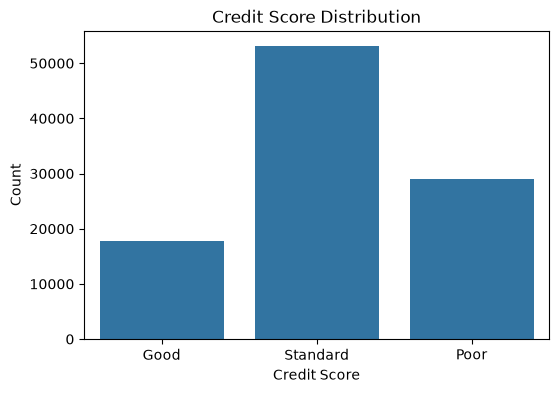

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count each Credit Score category
plt.figure(figsize=(6, 4))
sns.countplot(data=train_data, x='Credit_Score')

plt.title('Credit Score Distribution')
plt.xlabel('Credit Score')
plt.ylabel('Count')
plt.show()

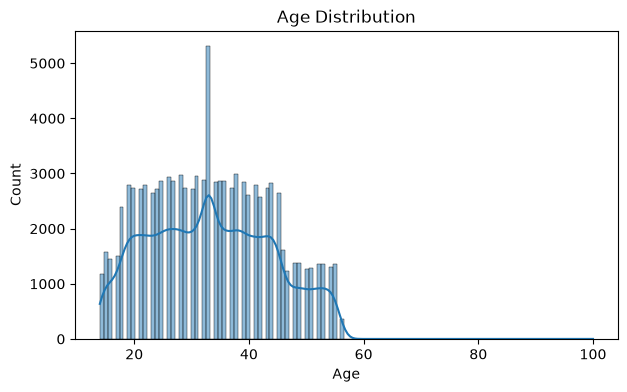

In [ ]:
# Age distribution
plt.figure(figsize=(7, 4))
sns.histplot(data=train_data, x='Age', kde=True)

plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

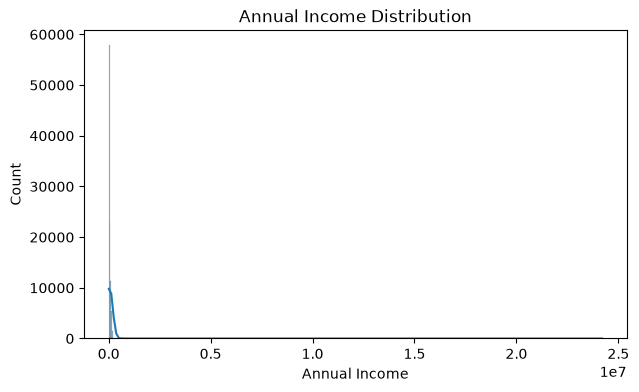

In [ ]:
# Annual income distribution
plt.figure(figsize=(7, 4))
sns.histplot(data=train_data, x='Annual_Income', kde=True)

plt.title('Annual Income Distribution')
plt.xlabel('Annual Income')
plt.ylabel('Count')
plt.show()

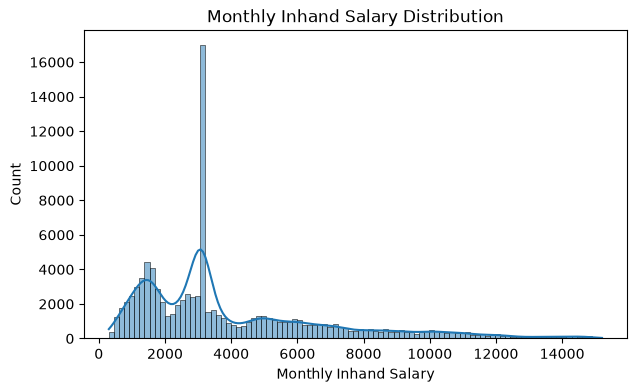

In [ ]:
# Monthly salary distribution
plt.figure(figsize=(7, 4))
sns.histplot(data=train_data, x='Monthly_Inhand_Salary', kde=True)

plt.title('Monthly Inhand Salary Distribution')
plt.xlabel('Monthly Inhand Salary')
plt.ylabel('Count')
plt.show()

In [ ]:
credit_numeric_cols = [
    'Num_Bank_Accounts',
    'Num_Credit_Card',
    'Interest_Rate',
    'Num_of_Loan',
    'Delay_from_due_date',
    'Num_of_Delayed_Payment',
    'Changed_Credit_Limit',
    'Num_Credit_Inquiries',
    'Outstanding_Debt',
    'Credit_Utilization_Ratio',
    'Credit_History_Age',
    'Total_EMI_per_month',
    'Amount_invested_monthly',
    'Monthly_Balance'
]

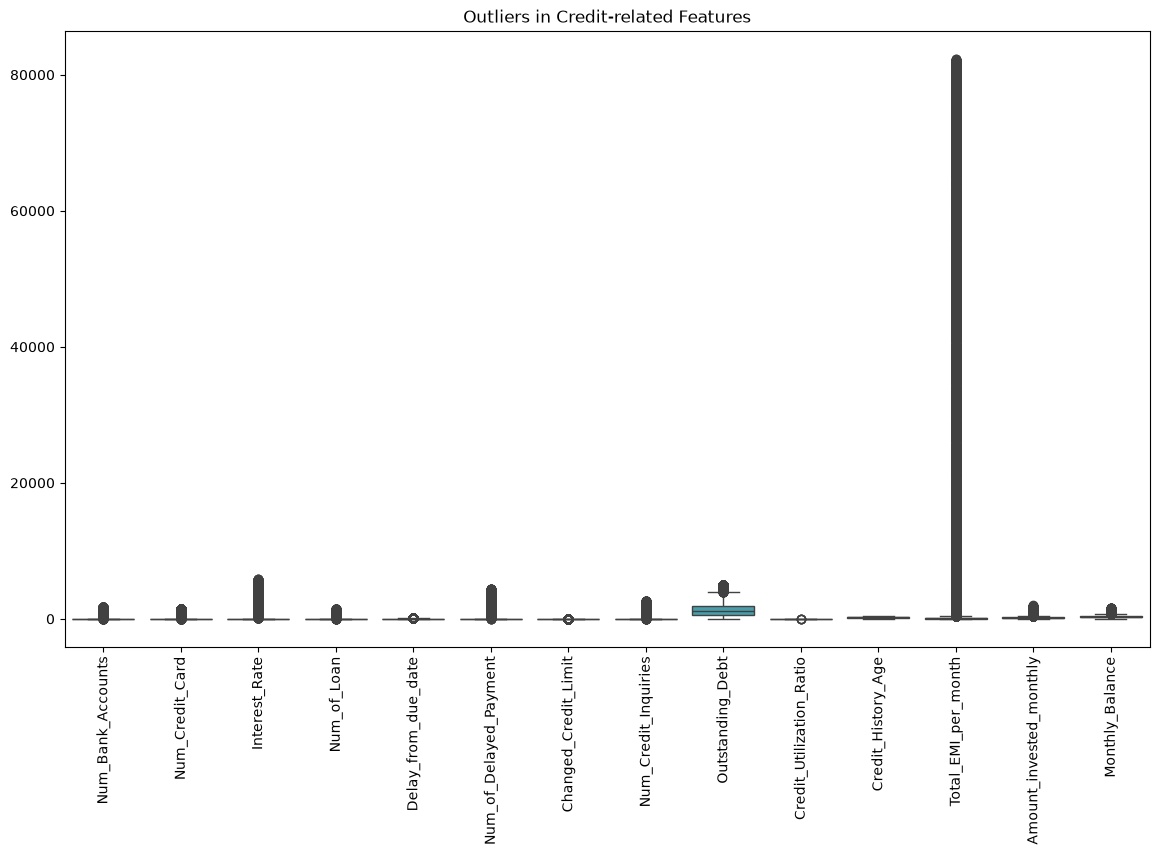

In [ ]:
# Check outliers in important numeric columns
plt.figure(figsize=(14, 8))

sns.boxplot(data=train_data[credit_numeric_cols])

plt.xticks(rotation=90)
plt.title('Outliers in Credit-related Features')
plt.show()

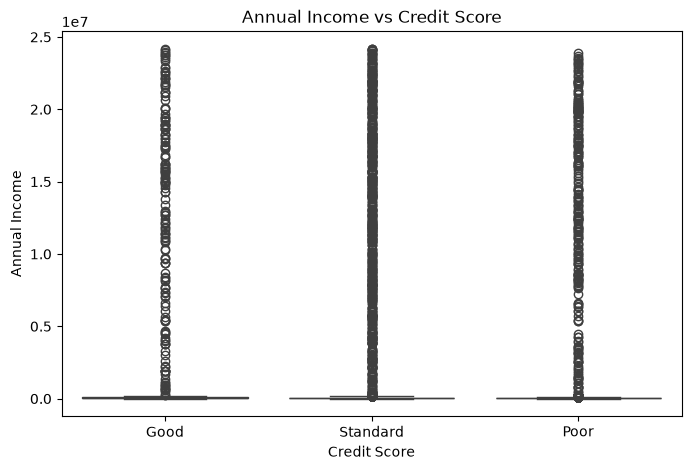

In [ ]:
# Annual Income vs Credit Score
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=train_data,
    x='Credit_Score',
    y='Annual_Income'
)

plt.title('Annual Income vs Credit Score')
plt.xlabel('Credit Score')
plt.ylabel('Annual Income')
plt.show()

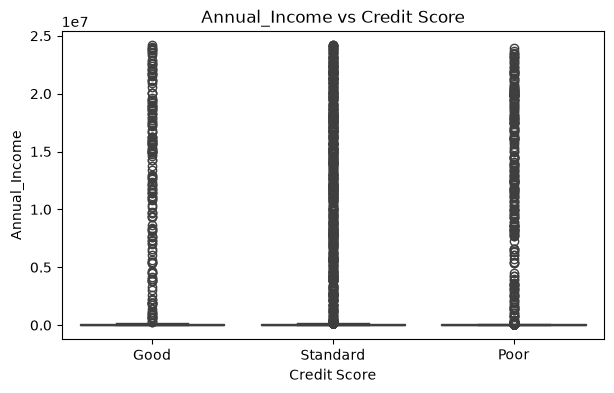

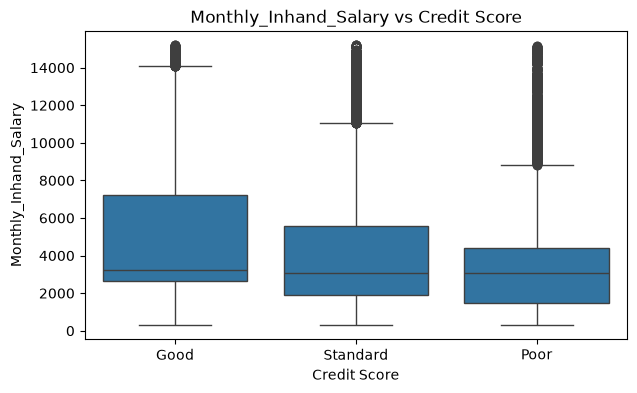

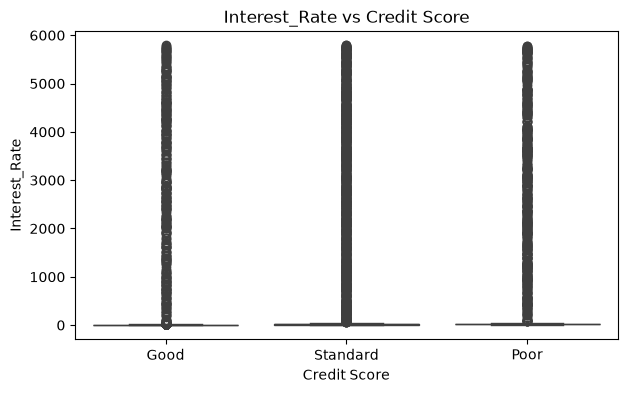

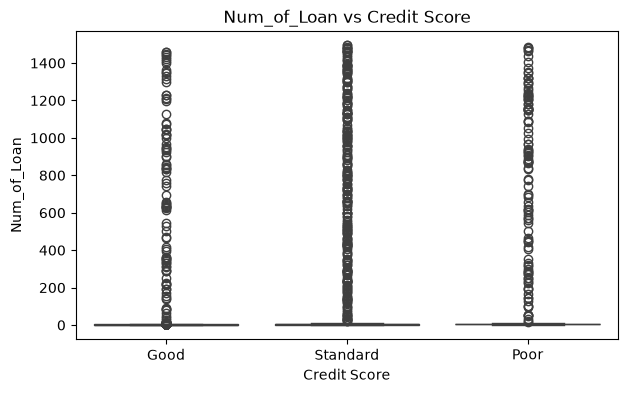

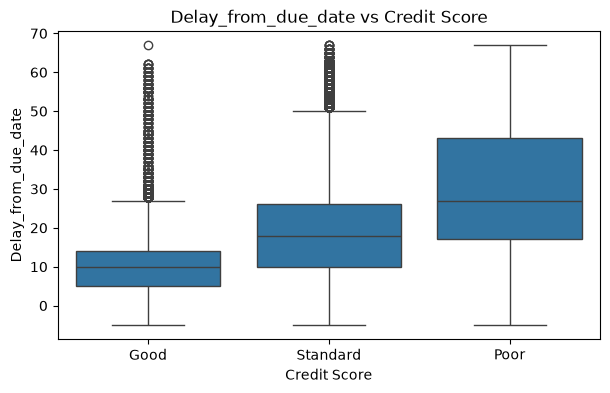

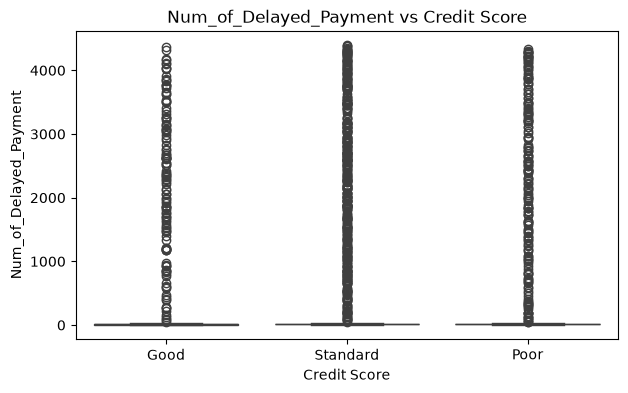

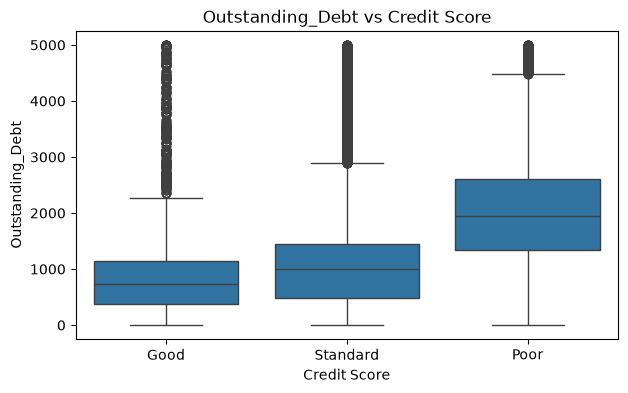

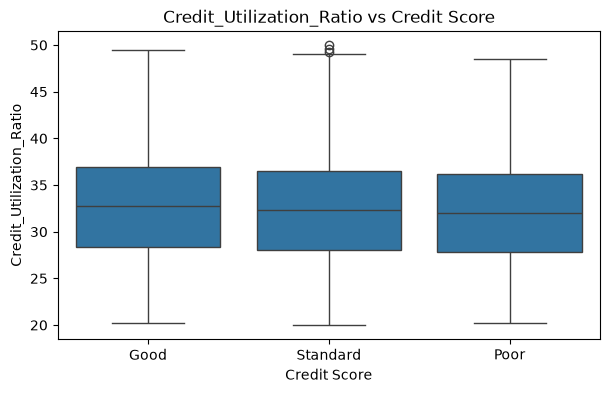

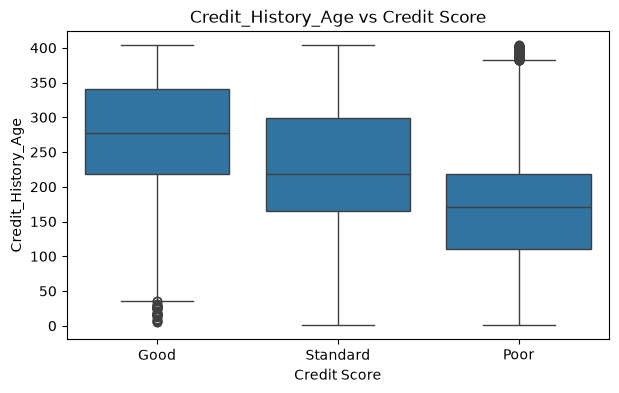

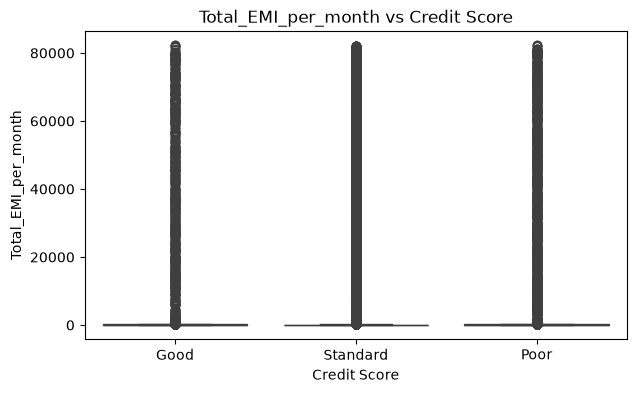

In [ ]:
important_features = [
    'Annual_Income',
    'Monthly_Inhand_Salary',
    'Interest_Rate',
    'Num_of_Loan',
    'Delay_from_due_date',
    'Num_of_Delayed_Payment',
    'Outstanding_Debt',
    'Credit_Utilization_Ratio',
    'Credit_History_Age',
    'Total_EMI_per_month'
]

for col in important_features:

    plt.figure(figsize=(7, 4))

    sns.boxplot(
        data=train_data,
        x='Credit_Score',
        y=col
    )

    plt.title(f'{col} vs Credit Score')
    plt.xlabel('Credit Score')
    plt.ylabel(col)

    plt.show()

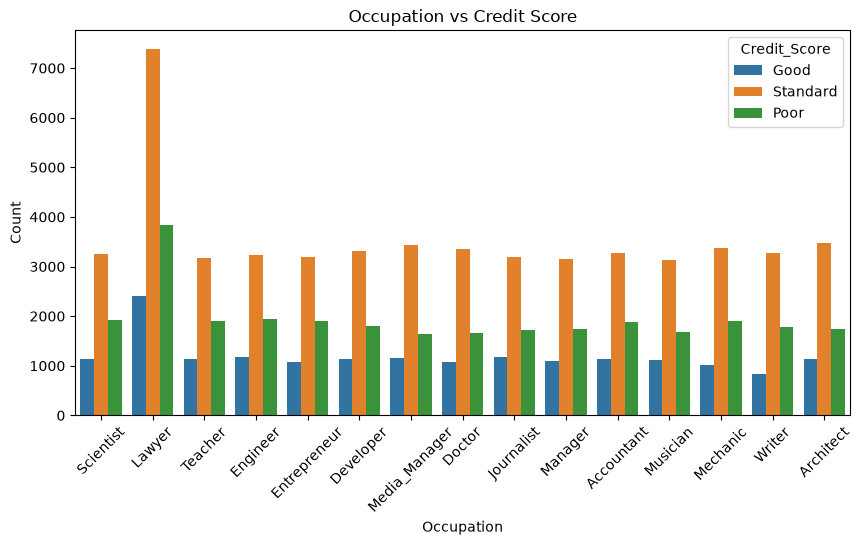

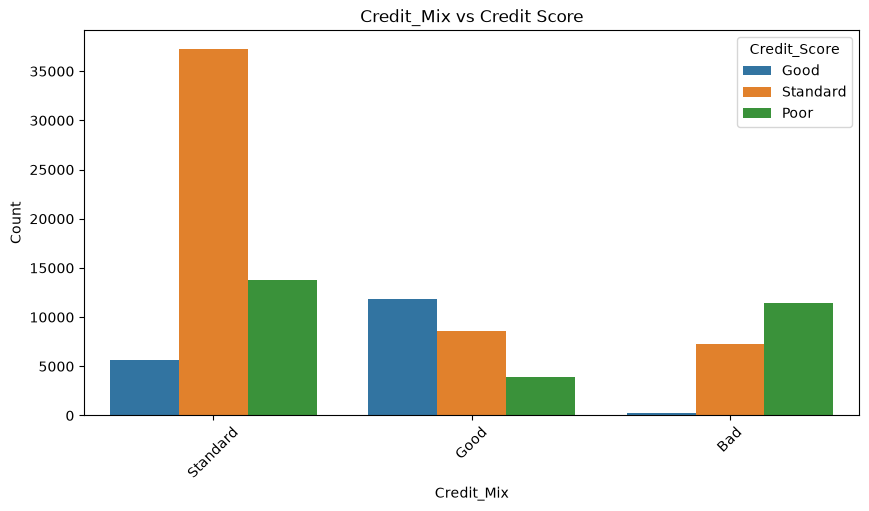

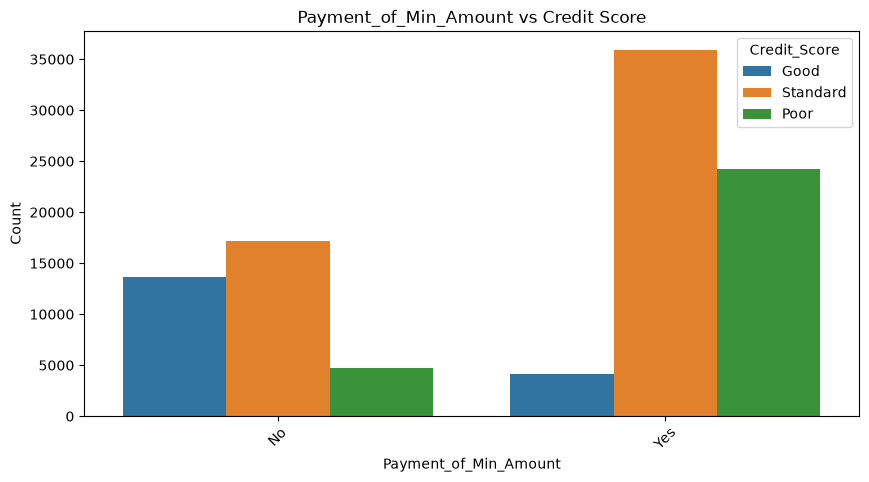

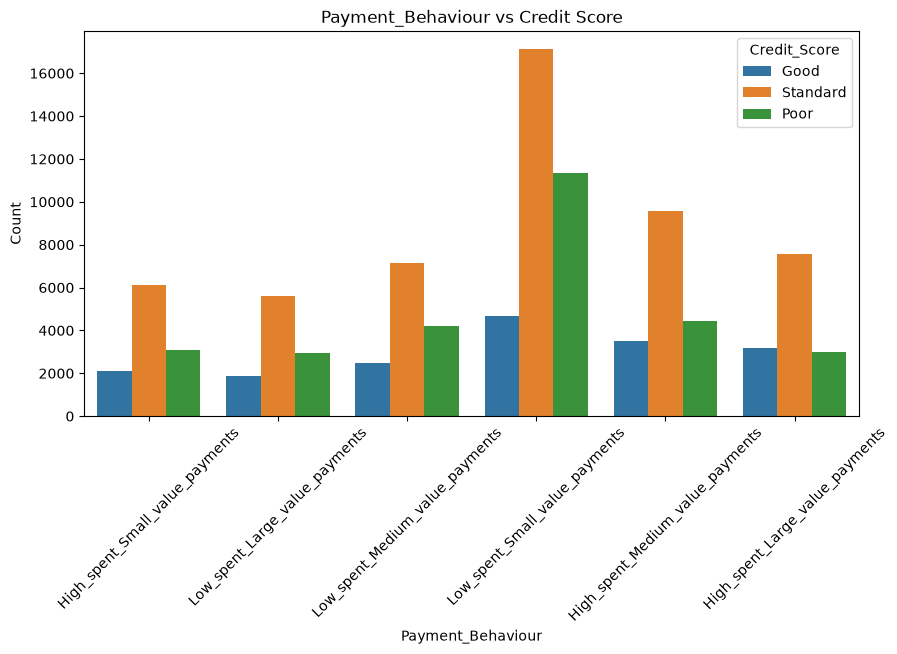

In [ ]:
categorical_cols = [
    'Occupation',
    'Credit_Mix',
    'Payment_of_Min_Amount',
    'Payment_Behaviour'
]

for col in categorical_cols:

    plt.figure(figsize=(10, 5))

    sns.countplot(
        data=train_data,
        x=col,
        hue='Credit_Score'
    )

    plt.title(f'{col} vs Credit Score')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.xticks(rotation=45)

    plt.show()

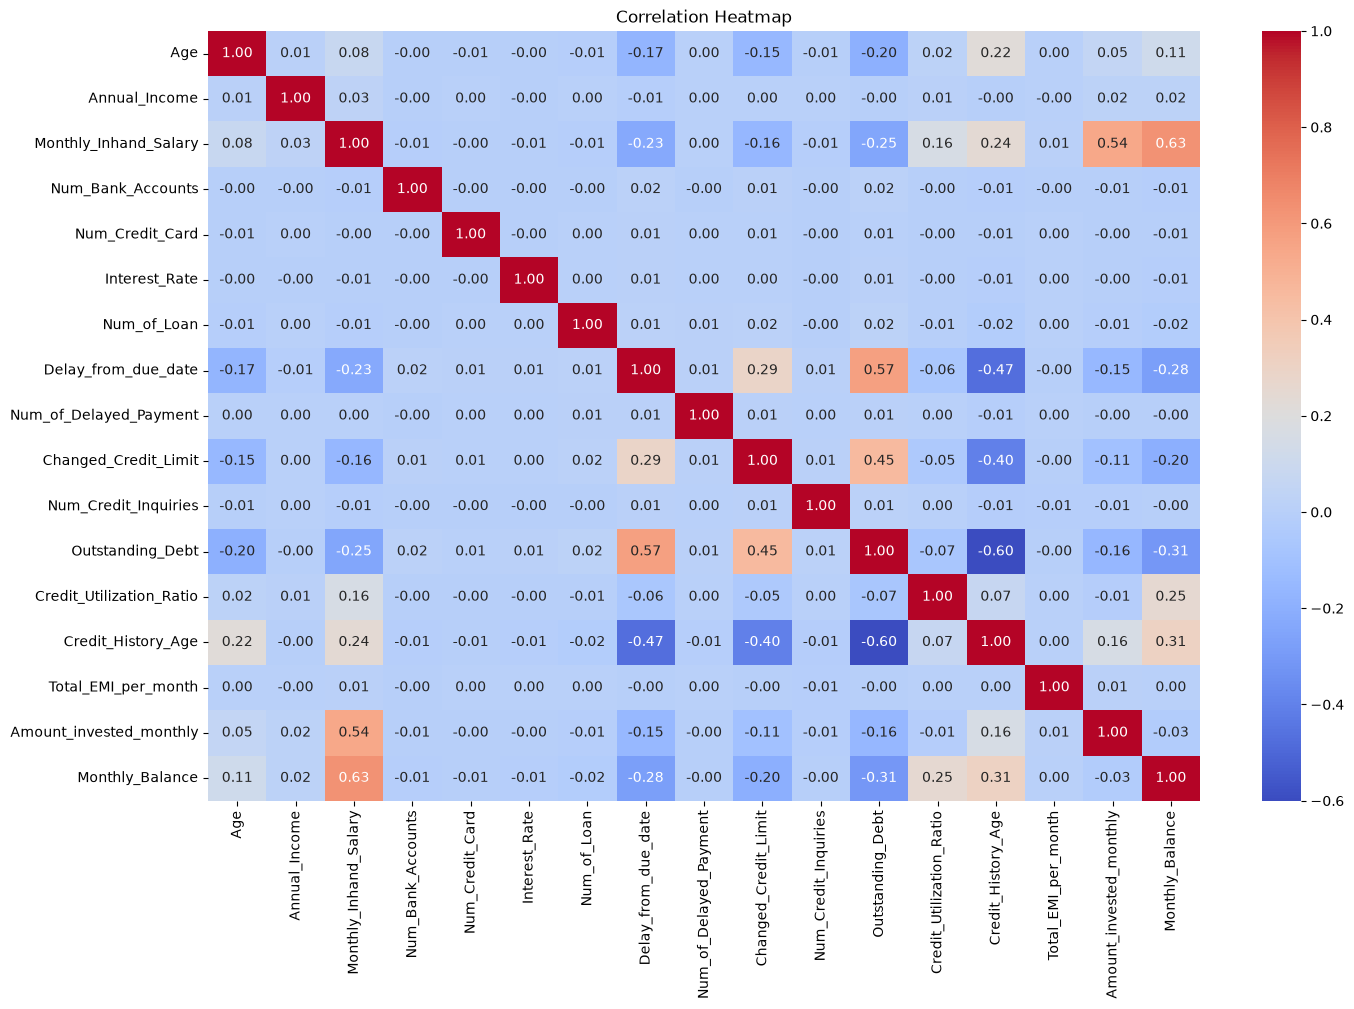

In [ ]:
# Select numeric columns
numeric_data = train_data.select_dtypes(include=['int64', 'float64'])

# Calculate correlation
correlation = numeric_data.corr()

# Draw heatmap
plt.figure(figsize=(16, 10))

sns.heatmap(
    correlation,
    annot=True,
    fmt='.2f',
    cmap='coolwarm'
)

plt.title('Correlation Heatmap')
plt.show()

# encoding

In [ ]:
# Convert Credit_Mix into ordered numbers

credit_mix_map = {
    'Bad': 0,
    'Standard': 1,
    'Good': 2
}

train_data['Credit_Mix'] = train_data['Credit_Mix'].map(credit_mix_map)

test_data['Credit_Mix'] = test_data['Credit_Mix'].map(credit_mix_map)

In [ ]:
# Convert Yes/No into 1/0

payment_map = {
    'No': 0,
    'Yes': 1
}

train_data['Payment_of_Min_Amount'] = train_data['Payment_of_Min_Amount'].map(payment_map)

test_data['Payment_of_Min_Amount'] = test_data['Payment_of_Min_Amount'].map(payment_map)

In [ ]:
# Create One-Hot Encoder

occupation_encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

# Fit on train and transform train
occupation_train = occupation_encoder.fit_transform(
    train_data[['Occupation']]
)

# Transform test using the same encoder
occupation_test = occupation_encoder.transform(
    test_data[['Occupation']]
)

# Get new column names
occupation_columns = occupation_encoder.get_feature_names_out(
    ['Occupation']
)

# Convert to DataFrame
occupation_train = pd.DataFrame(
    occupation_train,
    columns=occupation_columns,
    index=train_data.index
)

occupation_test = pd.DataFrame(
    occupation_test,
    columns=occupation_columns,
    index=test_data.index
)

In [ ]:
# Remove the original Occupation column

train_data.drop('Occupation', axis=1, inplace=True)
test_data.drop('Occupation', axis=1, inplace=True)

In [ ]:
# Add the new encoded columns

train_data = pd.concat(
    [train_data, occupation_train],
    axis=1
)

test_data = pd.concat(
    [test_data, occupation_test],
    axis=1
)

In [ ]:
# Create One-Hot Encoder for Payment_Behaviour

payment_encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

# Fit on train data
payment_train = payment_encoder.fit_transform(
    train_data[['Payment_Behaviour']]
)

# Transform test data
payment_test = payment_encoder.transform(
    test_data[['Payment_Behaviour']]
)

# Get new column names
payment_columns = payment_encoder.get_feature_names_out(
    ['Payment_Behaviour']
)

# Convert to DataFrame
payment_train = pd.DataFrame(
    payment_train,
    columns=payment_columns,
    index=train_data.index
)

payment_test = pd.DataFrame(
    payment_test,
    columns=payment_columns,
    index=test_data.index
)

In [ ]:
# Remove original Payment_Behaviour column

train_data.drop('Payment_Behaviour', axis=1, inplace=True)
test_data.drop('Payment_Behaviour', axis=1, inplace=True)

In [ ]:
# Add encoded Payment_Behaviour columns

train_data = pd.concat(
    [train_data, payment_train],
    axis=1
)

test_data = pd.concat(
    [test_data, payment_test],
    axis=1
)

In [ ]:
# Create One-Hot Encoder for Month

month_encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

# Fit on train data
month_train = month_encoder.fit_transform(
    train_data[['Month']]
)

# Transform test data
month_test = month_encoder.transform(
    test_data[['Month']]
)

# Get new column names
month_columns = month_encoder.get_feature_names_out(
    ['Month']
)

# Convert to DataFrame
month_train = pd.DataFrame(
    month_train,
    columns=month_columns,
    index=train_data.index
)

month_test = pd.DataFrame(
    month_test,
    columns=month_columns,
    index=test_data.index
)

In [ ]:
# Remove original Month column

train_data.drop('Month', axis=1, inplace=True)
test_data.drop('Month', axis=1, inplace=True)

In [ ]:
# Add encoded Month columns

train_data = pd.concat(
    [train_data, month_train],
    axis=1
)

test_data = pd.concat(
    [test_data, month_test],
    axis=1
)

In [ ]:
# apply Type_of_Loan column multi-label binary encoding
loan_types = [
    'Auto Loan',
    'Credit-Builder Loan',
    'Debt Consolidation Loan',
    'Home Equity Loan',
    'Mortgage Loan',
    'Not Specified',
    'Payday Loan',
    'Personal Loan',
    'Student Loan'
]

for loan in loan_types:
    train_data[loan] = train_data['Type_of_Loan'].fillna('').str.contains(
        loan, regex=False
    ).astype(int)

    test_data[loan] = test_data['Type_of_Loan'].fillna('').str.contains(
        loan, regex=False
    ).astype(int)

# Drop original text column  
train_data.drop('Type_of_Loan', axis=1, inplace=True)
test_data.drop('Type_of_Loan', axis=1, inplace=True)

In [ ]:
# Show all column names
print(train_data.columns.tolist())

['Age', 'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Num_Credit_Inquiries', 'Credit_Mix', 'Outstanding_Debt', 'Credit_Utilization_Ratio', 'Credit_History_Age', 'Payment_of_Min_Amount', 'Total_EMI_per_month', 'Amount_invested_monthly', 'Monthly_Balance', 'Credit_Score', 'Occupation_Accountant', 'Occupation_Architect', 'Occupation_Developer', 'Occupation_Doctor', 'Occupation_Engineer', 'Occupation_Entrepreneur', 'Occupation_Journalist', 'Occupation_Lawyer', 'Occupation_Manager', 'Occupation_Mechanic', 'Occupation_Media_Manager', 'Occupation_Musician', 'Occupation_Scientist', 'Occupation_Teacher', 'Occupation_Writer', 'Payment_Behaviour_High_spent_Large_value_payments', 'Payment_Behaviour_High_spent_Medium_value_payments', 'Payment_Behaviour_High_spent_Small_value_payments', 'Payment_Behaviour_Low_spent_Large_value_payments', 'Payment_Behaviour_Low

In [ ]:

# Force Pandas to display all columns without truncating them
pd.set_option('display.max_columns', None)

# Now print your first 5 rows
print(train_data.head(20))


     Age  Annual_Income  Monthly_Inhand_Salary  Num_Bank_Accounts  \
0   23.0       19114.12            1824.843333                3.0   
1   23.0       19114.12            3093.745000                3.0   
2   33.0       19114.12            3093.745000                3.0   
3   23.0       19114.12            3093.745000                3.0   
4   23.0       19114.12            1824.843333                3.0   
5   23.0       19114.12            3093.745000                3.0   
6   23.0       19114.12            1824.843333                3.0   
7   23.0       19114.12            1824.843333                3.0   
8   28.0       34847.84            3037.986667                2.0   
9   28.0       34847.84            3037.986667                2.0   
10  28.0       34847.84            3037.986667                2.0   
11  28.0       34847.84            3093.745000                2.0   
12  28.0       34847.84            3037.986667                2.0   
13  28.0       34847.84           

In [ ]:
print("Train shape:", train_data.shape)
print("Test shape:", test_data.shape)

Train shape: (100000, 58)
Test shape: (50000, 57)


In [ ]:
# Check target classes
print(train_data["Credit_Score"].value_counts())


Credit_Score
Standard    53174
Poor        28998
Good        17828
Name: count, dtype: int64


In [ ]:
# Check target percentages
print(
    train_data["Credit_Score"]
    .value_counts(normalize=True) * 100
)


Credit_Score
Standard    53.174
Poor        28.998
Good        17.828
Name: proportion, dtype: float64


In [ ]:
# X = input features
# y = answer that we want the model to predict

X = train_data.drop(columns=["Credit_Score"])

y = train_data["Credit_Score"]

# Test data contains only input features
X_test = test_data.copy()

print("X shape:", X.shape)
print("y shape:", y.shape)
print("X_test shape:", X_test.shape)


X shape: (100000, 57)
y shape: (100000,)
X_test shape: (50000, 57)


In [ ]:
# Convert Credit_Score text into numbers

target_mapping = {
    "Poor": 0,
    "Standard": 1,
    "Good": 2
}

y = y.map(target_mapping)

print(y.head())



0    2
1    2
2    2
3    2
4    2
Name: Credit_Score, dtype: int64


In [ ]:
# Check the unique target values

print(y.unique())


[2 1 0]


In [ ]:
# Check target counts

print(y.value_counts())


Credit_Score
1    53174
0    28998
2    17828
Name: count, dtype: int64


In [ ]:
# Check whether Credit_Score has missing values

print(
    "Missing target values:",
    y.isnull().sum()
)


Missing target values: 0


In [ ]:
# Replace infinity values with NaN

X = X.replace(
    [np.inf, -np.inf],
    np.nan
)

X_test = X_test.replace(
    [np.inf, -np.inf],
    np.nan
)

print("Infinity values cleaned.")


Infinity values cleaned.


In [ ]:
# Convert all columns to numeric

X = X.apply(
    pd.to_numeric,
    errors="coerce"
)

X_test = X_test.apply(
    pd.to_numeric,
    errors="coerce"
)

print("Data converted to numeric.")


Data converted to numeric.


In [ ]:
# Count missing values in training data

missing_values = X.isnull().sum()

print(
    missing_values[missing_values > 0]
    .sort_values(ascending=False)
)


Series([], dtype: int64)


In [ ]:
# Fix impossible Age values

X.loc[
    (X["Age"] < 18) | (X["Age"] > 100),
    "Age"
] = np.nan

X_test.loc[
    (X_test["Age"] < 18) | (X_test["Age"] > 100),
    "Age"
] = np.nan

print("Age cleaned.")


Age cleaned.


In [ ]:
# Fix impossible Interest_Rate values

X.loc[
    (X["Interest_Rate"] < 0) |
    (X["Interest_Rate"] > 100),
    "Interest_Rate"
] = np.nan

X_test.loc[
    (X_test["Interest_Rate"] < 0) |
    (X_test["Interest_Rate"] > 100),
    "Interest_Rate"
] = np.nan

print("Interest rate cleaned.")


Interest rate cleaned.


In [ ]:
from sklearn.model_selection import train_test_split

# Split the data

X_train, X_valid, y_train, y_valid = train_test_split(

    X,
    y,

    test_size=0.20,

    random_state=42,

    stratify=y
)

print("X_train:", X_train.shape)
print("X_valid:", X_valid.shape)
print("y_train:", y_train.shape)
print("y_valid:", y_valid.shape)


X_train: (80000, 57)
X_valid: (20000, 57)
y_train: (80000,)
y_valid: (20000,)


In [ ]:
# Check training target

print("y_train unique values:")
print(y_train.unique())

print("\ny_valid unique values:")
print(y_valid.unique())


y_train unique values:
[1 0 2]

y_valid unique values:
[1 0 2]


In [ ]:
# Check whether train and test have the same feature columns

print("Number of training features:", X.shape[1])
print("Number of test features:", X_test.shape[1])


Number of training features: 57
Number of test features: 57


In [ ]:
from sklearn.impute import SimpleImputer

# Create an imputer

imputer = SimpleImputer(
    strategy="median"
)

# Learn median from training data
X_train_imp = imputer.fit_transform(X_train)

# Apply same median to validation
X_valid_imp = imputer.transform(X_valid)

# Apply same median to test
X_test_imp = imputer.transform(X_test)

print("Missing values handled.")


Missing values handled.


In [ ]:
# Create XGBoost model

xgb_model = XGBClassifier(

    n_estimators=500,

    learning_rate=0.05,

    max_depth=8,

    min_child_weight=3,

    subsample=0.8,

    colsample_bytree=0.8,

    reg_alpha=0.1,

    reg_lambda=1,

    objective="multi:softmax",

    num_class=3,

    eval_metric="mlogloss",

    tree_method="hist",

    random_state=42,

    n_jobs=-1
)


In [ ]:
# Train XGBoost

xgb_model.fit(
    X_train,
    y_train,

    eval_set=[
        (X_valid, y_valid)
    ],

    verbose=100
)

print("XGBoost training finished.")


[0]	validation_0-mlogloss:0.97834
[100]	validation_0-mlogloss:0.61496
[200]	validation_0-mlogloss:0.58046
[300]	validation_0-mlogloss:0.55440
[400]	validation_0-mlogloss:0.53509
[499]	validation_0-mlogloss:0.52039
XGBoost training finished.


In [ ]:
# Predict validation data

xgb_pred = xgb_model.predict(X_valid)

print("First 20 predictions:")
print(xgb_pred[:20])


First 20 predictions:
[0 1 0 1 0 1 0 1 1 0 1 1 0 1 0 1 2 0 1 0]


In [ ]:
# Calculate accuracy

xgb_accuracy = accuracy_score(
    y_valid,
    xgb_pred
)

print(
    "XGBoost Accuracy:",
    xgb_accuracy
)

print(
    "XGBoost Accuracy (%):",
    xgb_accuracy * 100
)


XGBoost Accuracy: 0.78345
XGBoost Accuracy (%): 78.345


In [ ]:
# Calculate Macro F1

xgb_f1 = f1_score(
    y_valid,
    xgb_pred,
    average="macro"
)

print(
    "XGBoost Macro F1:",
    xgb_f1
)


XGBoost Macro F1: 0.7694913488788332


In [ ]:
# Detailed classification report

print(
    classification_report(
        y_valid,
        xgb_pred,
        target_names=[
            "Poor",
            "Standard",
            "Good"
        ]
    )
)


              precision    recall  f1-score   support

        Poor       0.78      0.77      0.78      5799
    Standard       0.80      0.81      0.81     10635
        Good       0.73      0.72      0.72      3566

    accuracy                           0.78     20000
   macro avg       0.77      0.77      0.77     20000
weighted avg       0.78      0.78      0.78     20000



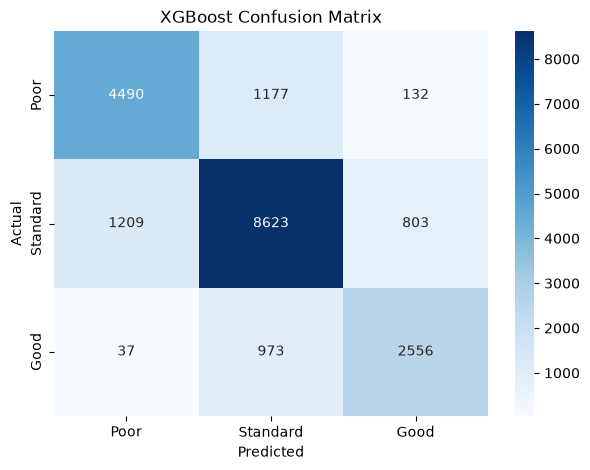

In [ ]:
# Create confusion matrix

cm = confusion_matrix(
    y_valid,
    xgb_pred
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",

    xticklabels=[
        "Poor",
        "Standard",
        "Good"
    ],

    yticklabels=[
        "Poor",
        "Standard",
        "Good"
    ]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title("XGBoost Confusion Matrix")

plt.show()


In [ ]:
# Create LightGBM model

lgb_model = LGBMClassifier(

    n_estimators=500,

    learning_rate=0.05,

    max_depth=8,

    num_leaves=31,

    subsample=0.8,

    colsample_bytree=0.8,

    random_state=42,

    n_jobs=-1,

    verbosity=-1
)


In [ ]:
# Train LightGBM

lgb_model.fit(
    X_train,
    y_train
)

print("LightGBM training finished.")


LightGBM training finished.


In [ ]:
# Predict validation data

lgb_pred = lgb_model.predict(
    X_valid
)


In [ ]:
# LightGBM accuracy

lgb_accuracy = accuracy_score(
    y_valid,
    lgb_pred
)

# LightGBM Macro F1

lgb_f1 = f1_score(
    y_valid,
    lgb_pred,
    average="macro"
)

print("LightGBM Accuracy:", lgb_accuracy)
print("LightGBM Accuracy (%):", lgb_accuracy * 100)
print("LightGBM Macro F1:", lgb_f1)


LightGBM Accuracy: 0.75445
LightGBM Accuracy (%): 75.445
LightGBM Macro F1: 0.7379666490197345


In [ ]:
# Create CatBoost model

cat_model = CatBoostClassifier(

    iterations=500,

    learning_rate=0.05,

    depth=8,

    loss_function="MultiClass",

    random_seed=42,

    verbose=100,

    thread_count=-1
)


In [ ]:
# Train CatBoost

cat_model.fit(
    X_train,
    y_train,

    eval_set=(
        X_valid,
        y_valid
    ),

    early_stopping_rounds=50
)

print("CatBoost training finished.")


0:	learn: 1.0651295	test: 1.0647707	best: 1.0647707 (0)	total: 226ms	remaining: 1m 52s
100:	learn: 0.6637132	test: 0.6695008	best: 0.6695008 (100)	total: 8.39s	remaining: 33.1s
200:	learn: 0.6309305	test: 0.6493579	best: 0.6493579 (200)	total: 21.3s	remaining: 31.7s
300:	learn: 0.6052976	test: 0.6351608	best: 0.6351608 (300)	total: 32.4s	remaining: 21.4s
400:	learn: 0.5808057	test: 0.6206817	best: 0.6206817 (400)	total: 43.2s	remaining: 10.7s
499:	learn: 0.5591933	test: 0.6088513	best: 0.6088513 (499)	total: 53.8s	remaining: 0us

bestTest = 0.6088512964
bestIteration = 499

CatBoost training finished.


In [ ]:
# Predict validation data

cat_pred = cat_model.predict(
    X_valid
)

# Convert to 1D array
cat_pred = cat_pred.ravel()


In [ ]:
# CatBoost accuracy

cat_accuracy = accuracy_score(
    y_valid,
    cat_pred
)

cat_f1 = f1_score(
    y_valid,
    cat_pred,
    average="macro"
)

print("CatBoost Accuracy:", cat_accuracy)
print("CatBoost Accuracy (%):", cat_accuracy * 100)
print("CatBoost Macro F1:", cat_f1)


CatBoost Accuracy: 0.74145
CatBoost Accuracy (%): 74.14500000000001
CatBoost Macro F1: 0.7209553791258312


In [ ]:
# Create Extra Trees model

extra_model = ExtraTreesClassifier(

    n_estimators=500,

    max_features="sqrt",

    class_weight="balanced",

    random_state=42,

    n_jobs=-1
)


In [ ]:
# Train Extra Trees

extra_model.fit(
    X_train_imp,
    y_train
)

print("Extra Trees training finished.")


Extra Trees training finished.


In [ ]:
# Predict validation data

extra_pred = extra_model.predict(
    X_valid_imp
)


In [ ]:
# Extra Trees accuracy

extra_accuracy = accuracy_score(
    y_valid,
    extra_pred
)

extra_f1 = f1_score(
    y_valid,
    extra_pred,
    average="macro"
)

print("Extra Trees Accuracy:", extra_accuracy)
print("Extra Trees Accuracy (%):", extra_accuracy * 100)
print("Extra Trees Macro F1:", extra_f1)


Extra Trees Accuracy: 0.7797
Extra Trees Accuracy (%): 77.97
Extra Trees Macro F1: 0.7603623870340557


In [ ]:
# Create Random Forest model

rf_model = RandomForestClassifier(

    n_estimators=500,

    max_features="sqrt",

    class_weight="balanced",

    random_state=42,

    n_jobs=-1
)


In [ ]:
# Train Random Forest

rf_model.fit(
    X_train_imp,
    y_train
)

print("Random Forest training finished.")


Random Forest training finished.


In [ ]:
# Predict validation data

rf_pred = rf_model.predict(
    X_valid_imp
)


In [ ]:
# Random Forest accuracy

rf_accuracy = accuracy_score(
    y_valid,
    rf_pred
)

rf_f1 = f1_score(
    y_valid,
    rf_pred,
    average="macro"
)

print("Random Forest Accuracy:", rf_accuracy)
print("Random Forest Accuracy (%):", rf_accuracy * 100)
print("Random Forest Macro F1:", rf_f1)


Random Forest Accuracy: 0.7902
Random Forest Accuracy (%): 79.02
Random Forest Macro F1: 0.7824265102430276


In [ ]:
# Compare all five models

results = pd.DataFrame({

    "Model": [
        "XGBoost",
        "LightGBM",
        "CatBoost",
        "Extra Trees",
        "Random Forest"
    ],

    "Accuracy": [
        xgb_accuracy,
        lgb_accuracy,
        cat_accuracy,
        extra_accuracy,
        rf_accuracy
    ],

    "Macro_F1": [
        xgb_f1,
        lgb_f1,
        cat_f1,
        extra_f1,
        rf_f1
    ]
})

# Sort from highest accuracy to lowest

results = results.sort_values(
    by="Accuracy",
    ascending=False
)

display(results)


,Model,Accuracy,Macro_F1
4,Random Forest,0.79020,0.782427
0,XGBoost,0.78345,0.769491
3,Extra Trees,0.77970,0.760362
1,LightGBM,0.75445,0.737967
2,CatBoost,0.74145,0.720955


#  Random forest model is best

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
#apply tuning


In [ ]:
# Different Random Forest settings to test

rf_params = {

    "n_estimators": [300, 500, 800, 1000],

    "max_depth": [None, 15, 20, 25, 30],

    "min_samples_split": [2, 5, 10],

    "min_samples_leaf": [1, 2, 4],

    "max_features": ["sqrt", "log2", 0.5],

    "class_weight": [None, "balanced"]
}


In [ ]:
# Base Random Forest model

rf_base = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)


In [ ]:
# Try different parameter combinations

rf_search = RandomizedSearchCV(

    estimator=rf_base,

    param_distributions=rf_params,

    n_iter=20,

    scoring="accuracy",

    cv=3,

    random_state=42,

    verbose=2,

    n_jobs=-1
)


In [ ]:
# Start tuning

rf_search.fit(
    X_train_imp,
    y_train
)


Fitting 3 folds for each of 20 candidates, totalling 60 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'class_weight': [None, 'balanced'], 'max_depth': [None, 15, ...], 'max_features': ['sqrt', 'log2', ...], 'min_samples_leaf': [1, 2, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a func

In [ ]:
# Show the best Random Forest settings

print("Best parameters:")
print(rf_search.best_params_)

print("\nBest cross-validation accuracy:")
print(rf_search.best_score_)


Best parameters:
{'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': None, 'class_weight': 'balanced'}

Best cross-validation accuracy:
0.7709125125848174


In [ ]:
# Get the best Random Forest

best_rf = rf_search.best_estimator_

# Predict validation data

rf_tuned_pred = best_rf.predict(
    X_valid_imp
)


In [ ]:
# Calculate tuned accuracy

rf_tuned_accuracy = accuracy_score(
    y_valid,
    rf_tuned_pred
)

print(
    "Tuned Random Forest Accuracy:",
    rf_tuned_accuracy
)

print(
    "Tuned Random Forest Accuracy (%):",
    rf_tuned_accuracy * 100
)


Tuned Random Forest Accuracy: 0.7942
Tuned Random Forest Accuracy (%): 79.42


In [ ]:
# Calculate tuned Macro F1

rf_tuned_f1 = f1_score(
    y_valid,
    rf_tuned_pred,
    average="macro"
)

print(
    "Tuned Random Forest Macro F1:",
    rf_tuned_f1
)


Tuned Random Forest Macro F1: 0.7872061757169165


In [ ]:
#Compare before and after tuning
print("====================================")
print("Random Forest BEFORE tuning")
print("Accuracy:", rf_accuracy)
print("Macro F1:", rf_f1)

print("\nRandom Forest AFTER tuning")
print("Accuracy:", rf_tuned_accuracy)
print("Macro F1:", rf_tuned_f1)
print("====================================")

#not very difference


Random Forest BEFORE tuning
Accuracy: 0.7902
Macro F1: 0.7824265102430276

Random Forest AFTER tuning
Accuracy: 0.7942
Macro F1: 0.7872061757169165


In [ ]:
from sklearn.model_selection import RandomizedSearchCV

# XGBoost parameters to test

xgb_params = {
    "n_estimators": [300, 500, 800],
    "learning_rate": [0.03, 0.05, 0.08, 0.1],
    "max_depth": [4, 6, 8, 10],
    "min_child_weight": [1, 3, 5],
    "subsample": [0.7, 0.8, 0.9],
    "colsample_bytree": [0.7, 0.8, 0.9],
    "gamma": [0, 0.1, 0.3],
    "reg_alpha": [0, 0.1, 0.5],
    "reg_lambda": [1, 2, 5]
}


In [ ]:
# Create base XGBoost model

xgb_base = XGBClassifier(
    objective="multi:softmax",
    num_class=3,
    eval_metric="mlogloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)


In [ ]:
# Test 20 random combinations

xgb_search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=xgb_params,
    n_iter=20,
    scoring="accuracy",
    cv=3,
    random_state=42,
    verbose=2,
    n_jobs=-1
)


In [ ]:
# Start XGBoost tuning

xgb_search.fit(
    X_train,
    y_train
)

print("XGBoost tuning completed.")


Fitting 3 folds for each of 20 candidates, totalling 60 fits
XGBoost tuning completed.


In [ ]:
#Show best parameters
print("Best XGBoost parameters:")
print(xgb_search.best_params_)

print("\nBest CV accuracy:")
print(xgb_search.best_score_)


Best XGBoost parameters:
{'subsample': 0.9, 'reg_lambda': 1, 'reg_alpha': 0.5, 'n_estimators': 800, 'min_child_weight': 1, 'max_depth': 10, 'learning_rate': 0.08, 'gamma': 0, 'colsample_bytree': 0.7}

Best CV accuracy:
0.7876124791521182


In [ ]:
# Get the best XGBoost model

best_xgb = xgb_search.best_estimator_


In [ ]:
# Predict validation data

xgb_tuned_pred = best_xgb.predict(
    X_valid
)


In [ ]:
# Calculate XGBoost accuracy

xgb_tuned_accuracy = accuracy_score(
    y_valid,
    xgb_tuned_pred
)

print(
    "Tuned XGBoost Accuracy:",
    xgb_tuned_accuracy
)

print(
    "Tuned XGBoost Accuracy (%):",
    xgb_tuned_accuracy * 100
)


Tuned XGBoost Accuracy: 0.8098
Tuned XGBoost Accuracy (%): 80.97999999999999


In [ ]:
# Calculate Macro F1

xgb_tuned_f1 = f1_score(
    y_valid,
    xgb_tuned_pred,
    average="macro"
)

print(
    "Tuned XGBoost Macro F1:",
    xgb_tuned_f1
)


Tuned XGBoost Macro F1: 0.7997427692843161


In [ ]:
print("====================================")
print("MODEL COMPARISON")
print("====================================")

print("\nTuned Random Forest")
print("Accuracy:", rf_tuned_accuracy)
print("Macro F1:", rf_tuned_f1)

print("\nTuned XGBoost")
print("Accuracy:", xgb_tuned_accuracy)
print("Macro F1:", xgb_tuned_f1)


MODEL COMPARISON

Tuned Random Forest
Accuracy: 0.7942
Macro F1: 0.7872061757169165

Tuned XGBoost
Accuracy: 0.8098
Macro F1: 0.7997427692843161


In [ ]:
# XGBoost is the best model

print("Best Model: XGBoost")
print("Validation Accuracy:", xgb_tuned_accuracy)
print("Validation Macro F1:", xgb_tuned_f1)

Best Model: XGBoost
Validation Accuracy: 0.8098
Validation Macro F1: 0.7997427692843161


In [ ]:
# Use all training data

X_full = X.copy()
y_full = y.copy()

print("X_full shape:", X_full.shape)
print("y_full shape:", y_full.shape)


X_full shape: (100000, 57)
y_full shape: (100000,)


In [ ]:
# Get the best parameters from XGBoost tuning

best_params = xgb_search.best_params_

print("Best XGBoost parameters:")
print(best_params)


Best XGBoost parameters:
{'subsample': 0.9, 'reg_lambda': 1, 'reg_alpha': 0.5, 'n_estimators': 800, 'min_child_weight': 1, 'max_depth': 10, 'learning_rate': 0.08, 'gamma': 0, 'colsample_bytree': 0.7}


In [ ]:
# Create final XGBoost model

final_xgb = XGBClassifier(
    **best_params,
    objective="multi:softmax",
    num_class=3,
    eval_metric="mlogloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

print("Final XGBoost model created.")


Final XGBoost model created.


In [ ]:
# Train final XGBoost model

final_xgb.fit(
    X_full,
    y_full
)

print("====================================")
print("FINAL MODEL TRAINED")
print("====================================")


FINAL MODEL TRAINED


In [ ]:
import pickle

# Save the trained model

with open("credit_score_xgboost.pkl", "wb") as file:
    pickle.dump(final_xgb, file)

print("Model saved successfully!")
print("File name: credit_score_xgboost.pkl")


Model saved successfully!
File name: credit_score_xgboost.pkl


In [ ]:
import os

print(
    "PKL file exists:",
    os.path.exists("credit_score_xgboost.pkl")
)


PKL file exists: True


In [ ]:
# Load the saved model

with open("credit_score_xgboost.pkl", "rb") as file:
    loaded_model = pickle.load(file)

print("PKL model loaded successfully!")


PKL model loaded successfully!


In [ ]:
# Predict test data

test_predictions = loaded_model.predict(X_test)

print("Number of predictions:", len(test_predictions))
print("First 20 predictions:")
print(test_predictions[:20])


Number of predictions: 50000
First 20 predictions:
[2 2 2 2 2 2 2 1 2 2 2 2 1 1 1 1 1 1 1 1]


In [ ]:
# Convert numeric predictions back to original labels

reverse_mapping = {
    0: "Poor",
    1: "Standard",
    2: "Good"
}

test_predictions_labels = pd.Series(
    test_predictions
).map(reverse_mapping)

print(test_predictions_labels.head(20))


0         Good
1         Good
2         Good
3         Good
4         Good
5         Good
6         Good
7     Standard
8         Good
9         Good
10        Good
11        Good
12    Standard
13    Standard
14    Standard
15    Standard
16    Standard
17    Standard
18    Standard
19    Standard
dtype: str


In [ ]:
# Count predicted classes

print(
    test_predictions_labels.value_counts()
)


Standard    25774
Poor        14968
Good         9258
Name: count, dtype: int64


In [ ]:
# Create dataframe

submission = pd.DataFrame({
    "Credit_Score": test_predictions_labels
})

print(submission.head())
print("Shape:", submission.shape)


  Credit_Score
0         Good
1         Good
2         Good
3         Good
4         Good
Shape: (50000, 1)


In [ ]:
# Save final predictions

submission.to_csv(
    "credit_score_predictions.csv",
    index=False
)

print("====================================")
print("DONE!")
print("====================================")
print("Model: credit_score_xgboost.pkl")
print("Predictions: credit_score_predictions.csv")


DONE!
Model: credit_score_xgboost.pkl
Predictions: credit_score_predictions.csv
